# Demo: yield curves, bond risk and Euro-Bund futures basis

A walkthrough of the four results of the README on the frozen public data in `data/sample/` (as of 27 October 2026). Each section calls the `ratescurve` package directly; `scripts/run_results.py` produces the published figures and tables.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ratescurve.calibration import bond_pricer
from ratescurve.data import ASOF, bunds_on, load_deliverables, load_estr, load_fgbl, load_ust_par, verify_manifest
from ratescurve.futures import basis, conversion_factor, delivery_date
from ratescurve.markets import build_eur_curve, build_usd_curve, eligible_bunds, out_of_sample
from ratescurve.pca import principal_components
from ratescurve.risk import key_rate_dv01, parallel_dv01

start = time.perf_counter()
verify_manifest()  # every frozen file matches its SHA-256
METHODS = ["monotone_convex", "log_linear_df", "linear_zero", "natural_cubic_zero"]
usd = {m: build_usd_curve(ASOF, m) for m in METHODS}
eur = {m: build_eur_curve(ASOF, m) for m in METHODS}
quotes = eligible_bunds(ASOF)
pd.DataFrame(
    {
        m: {
            "USD: max |price - 1| of the 14 par instruments": np.abs(usd[m].residuals).max(),
            "EUR: max |price error| of the 15 Bunds (per 100)": np.abs(eur[m].residuals).max(),
        }
        for m in METHODS
    }
).T

,USD: max |price - 1| of the 14 par instruments,EUR: max |price error| of the 15 Bunds (per 100)
monotone_convex,0.000000e+00,1.421085e-14
log_linear_df,0.000000e+00,0.000000e+00
linear_zero,1.110223e-16,0.000000e+00
natural_cubic_zero,0.000000e+00,0.000000e+00


## 1. Same instruments, same prices, different forwards

Every scheme reprices its calibration Bunds exactly, yet the instantaneous forward curves differ, and so do forward-starting rates.

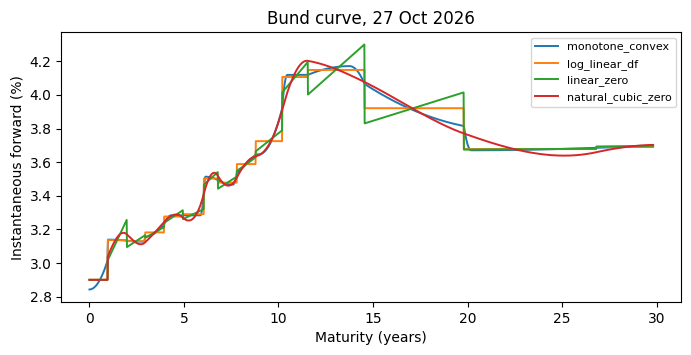

,10y10y forward (%),out-of-sample RMS (bp)
monotone_convex,4.009,2.939
log_linear_df,4.006,3.487
linear_zero,4.008,3.444
natural_cubic_zero,4.008,3.478


In [2]:
grid = np.linspace(1 / 365, eur["monotone_convex"].curve.t_max, 2000)
fig, ax = plt.subplots(figsize=(8, 3.5))
for m in METHODS:
    ax.plot(grid, eur[m].curve.forward(grid) * 100, lw=1.4, label=m)
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Instantaneous forward (%)")
ax.set_title("Bund curve, 27 Oct 2026")
ax.legend(fontsize=8)
plt.show()
pd.DataFrame(
    {
        m: {
            "10y10y forward (%)": 100 * eur[m].curve.discrete_forward(10, 20),
            "out-of-sample RMS (bp)": float(np.sqrt(np.mean(out_of_sample(eur[m], quotes)["residual_bp"] ** 2))),
        }
        for m in METHODS
    }
).T.round(3)

## 2. Key-rate DV01 of a Bund

Triangular zero-rate bumps on nine key tenors add up to a parallel shift, so the key-rate DV01s add up to the parallel DV01.

In [3]:
keys = (1, 2, 3, 5, 7, 10, 15, 20, 30)
curve = eur["monotone_convex"].curve
bullet = quotes[quotes["isin"] == "DE000BU2Z072"].iloc[0]  # DBR 3 08/15/36
value = bond_pricer(bullet["bond"], bullet["settle"], nominal=1e6)  # EUR 100mn nominal
krd = key_rate_dv01(value, curve, keys)
print(f"parallel DV01 EUR {parallel_dv01(value, curve):,.0f} per bp; sum of key-rate DV01s EUR {krd.sum():,.0f}")
pd.Series(krd.round(0) + 0.0, index=[f"{k}y" for k in keys], name="key-rate DV01 (EUR per bp)").to_frame().T

parallel DV01 EUR 83,644 per bp; sum of key-rate DV01s EUR 83,644


,1y,2y,3y,5y,7y,10y,15y,20y,30y
key-rate DV01 (EUR per bp),359.0,563.0,1349.0,2551.0,8981.0,69840.0,0.0,0.0,0.0


## 3. Principal components of daily Treasury curve changes

In [4]:
ust = load_ust_par()[["3M", "6M", "1Y", "2Y", "3Y", "5Y", "7Y", "10Y", "20Y", "30Y"]].dropna()
pca = principal_components((ust.diff().dropna() * 100).to_numpy(), k=3)
pd.DataFrame(
    pca.loadings, index=ust.columns, columns=[f"PC{i} ({v:.1%})" for i, v in enumerate(pca.explained, 1)]
).round(3).T

,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y
PC1 (83.0%),0.070,0.140,0.269,0.393,0.403,0.402,0.385,0.345,0.291,0.268
PC2 (10.7%),-0.168,-0.296,-0.438,-0.376,-0.214,-0.001,0.155,0.275,0.428,0.472
PC3 (2.9%),-0.726,-0.445,-0.170,0.208,0.276,0.161,0.084,-0.035,-0.187,-0.240


## 4. Euro-Bund futures (FGBL Dec-26): basket, conversion factors, net basis, implied repo

In [5]:
deliv = delivery_date(2026, 12)
fut = float(load_fgbl().set_index(["business_date", "contract"]).loc[(ASOF, "20261208"), "settlement"])
repo = float(load_estr().loc[str(ASOF)]) / 100
day = bunds_on(ASOF).set_index("isin")
dl = load_deliverables()
basket = dl[(dl["product"] == "FGBL") & (dl["contract"] == "20261208")]
rows = []
for _, d in basket.iterrows():
    bond = day.loc[d["isin"], "bond"]
    cf = round(conversion_factor(bond, deliv), 6)
    b = basis(bond, float(day.loc[d["isin"], "clean"]), day.loc[d["isin"], "settle"], deliv, fut, cf, repo)
    rows.append(
        {
            "bond": day.loc[d["isin"], "description"],
            "CF (computed)": cf,
            "CF (Eurex)": d["conversion_factor"],
            "net basis (cents)": 100 * b.net_basis,
            "implied repo (%)": 100 * b.implied_repo,
        }
    )
print(f"FGBL Dec-26 settlement {fut:.2f}, delivery {deliv}, financing at €STR {100 * repo:.3f}%")
pd.DataFrame(rows).round({"CF (computed)": 6, "CF (Eurex)": 6, "net basis (cents)": 1, "implied repo (%)": 2})

FGBL Dec-26 settlement 122.09, delivery 2026-12-10, financing at €STR 2.440%


,bond,CF (computed),CF (Eurex),net basis (cents),implied repo (%)
0,DBR 2.6 08/15/35,0.774902,0.774902,-1.6,2.58
1,DBR 2.9 02/15/36,0.785735,0.785735,59.7,-2.74
2,DBR 3 08/15/36,0.784157,0.784157,128.6,-8.81


In [6]:
print(f"Analysis cells executed in {time.perf_counter() - start:.1f} s")

Analysis cells executed in 1.2 s
